# Module 03 — Eigenvalues, SVD and PCA

This notebook walks through the ideas of the module with code you can edit and re-run:
eigenvectors as the directions a matrix only stretches, power iteration and PageRank, the
spectral theorem, the singular value decomposition, low-rank approximation and image
compression, PCA from scratch on the Iris data, the pseudo-inverse, and the condition number.

Read the [concept guide](README.md) first, or keep it open alongside — every section here
mirrors a numbered section there. Code cells build each object **from scratch in NumPy**
first and then check against the library call that does the same.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(42)
plt.rcParams["figure.figsize"] = (7, 4)
np.set_printoptions(precision=4, suppress=True)

## 1. Eigenvectors and eigenvalues — the directions a matrix only stretches

A square matrix $A$ moves every vector. A vector $v \ne 0$ with

$$A v = \lambda v$$

is only *scaled* (by the eigenvalue $\lambda$), never turned. For a $2\times2$ matrix the
eigenvalues solve the characteristic polynomial $\lambda^2 - \operatorname{tr}(A)\lambda + \det(A) = 0$.

Below we take $A = \begin{pmatrix} 4 & 1 \\ 2 & 3 \end{pmatrix}$, solve the polynomial by hand,
compare with `np.linalg.eig`, and draw what $A$ does to a grid. Watch the two coloured arrows:
they are the eigenvectors, and they come out pointing the same way they went in.

characteristic polynomial:  lambda^2 - 7 lambda + 10 = 0
eigenvalues by hand:        [5. 2.]
np.linalg.eig eigenvalues:  [5. 2.]
eigenvectors (unit length, as columns):
[[ 0.7071  0.4472]
 [ 0.7071 -0.8944]]
  A v1 = [3.5355 3.5355]   lambda1 v1 = [3.5355 3.5355]
  A v2 = [ 0.8944 -1.7889]   lambda2 v2 = [ 0.8944 -1.7889]
angle between eigenvectors: 71.6 degrees  (not orthogonal: A is not symmetric)


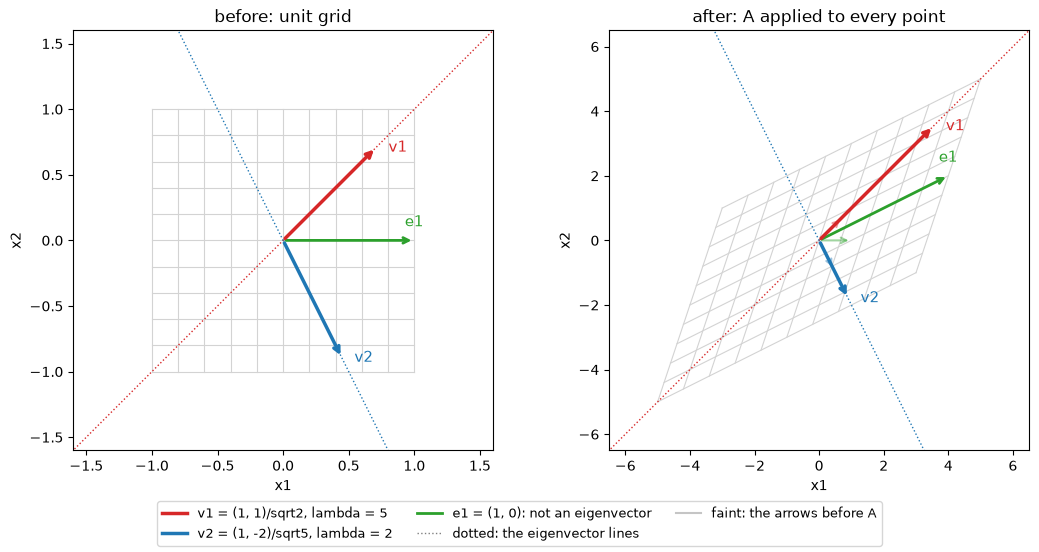

In [2]:
A = np.array([[4., 1.],
              [2., 3.]])

# --- eigenvalues by hand: lambda^2 - tr*lambda + det = 0
tr, det = np.trace(A), np.linalg.det(A)
disc = np.sqrt(tr**2 - 4 * det)
lam_hand = np.array([(tr + disc) / 2, (tr - disc) / 2])
print(f"characteristic polynomial:  lambda^2 - {tr:.0f} lambda + {det:.0f} = 0")
print("eigenvalues by hand:       ", lam_hand)

# --- NumPy
w, V = np.linalg.eig(A)
order = np.argsort(-w.real)              # sort descending so the two agree
w, V = w[order].real, V[:, order].real
V = V * np.sign(V[0])                    # sign convention: first entry positive, as in the README
print("np.linalg.eig eigenvalues: ", w)
print("eigenvectors (unit length, as columns):")
print(V)
for i in range(2):
    print(f"  A v{i+1} = {A @ V[:, i]}   lambda{i+1} v{i+1} = {w[i] * V[:, i]}")
print("angle between eigenvectors: %.1f degrees  (not orthogonal: A is not symmetric)"
      % np.degrees(np.arccos(abs(V[:, 0] @ V[:, 1]))))

# --- the grid picture
ts = np.linspace(-1, 1, 11)
e1 = np.array([1., 0.])
cols = ["tab:red", "tab:blue"]
fig, axes = plt.subplots(1, 2, figsize=(11, 5.4))
for ax, M, title, lim in [(axes[0], np.eye(2), "before: unit grid", 1.6),
                          (axes[1], A, "after: A applied to every point", 6.5)]:
    for t in ts:
        for seg in (np.array([[t, t], [-1, 1]]), np.array([[-1, 1], [t, t]])):
            p = M @ seg
            ax.plot(p[0], p[1], color="lightgray", lw=0.8)
    for i, c in enumerate(cols):        # the eigenvector LINES: A maps each of them onto itself
        ax.plot([-2 * lim * V[0, i], 2 * lim * V[0, i]], [-2 * lim * V[1, i], 2 * lim * V[1, i]],
                ":", color=c, lw=1)
    if M is A:                          # faint copies of the input arrows, for comparison
        for u, c in [(e1, "tab:green"), (V[:, 0], cols[0]), (V[:, 1], cols[1])]:
            ax.annotate("", xy=u, xytext=(0, 0),
                        arrowprops=dict(arrowstyle="->", color=c, lw=1.5, alpha=0.45))
    g = M @ e1                          # a generic vector: it gets turned
    ax.annotate("", xy=g, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="tab:green", lw=2))
    ax.text(g[0], g[1] + 0.05 * lim, "e1", color="tab:green", ha="center", va="bottom", fontsize=11)
    for i, c in enumerate(cols):
        u = M @ V[:, i]
        ax.annotate("", xy=u, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=c, lw=2.5))
        ax.text(u[0] + 0.06 * lim, u[1], f"v{i+1}", color=c, va="center", fontsize=11)
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim); ax.set_aspect("equal")
    ax.set_title(title); ax.set_xlabel("x1"); ax.set_ylabel("x2")
from matplotlib.lines import Line2D
handles = [Line2D([], [], color=cols[0], lw=2.5, label="v1 = (1, 1)/sqrt2, lambda = 5"),
           Line2D([], [], color=cols[1], lw=2.5, label="v2 = (1, -2)/sqrt5, lambda = 2"),
           Line2D([], [], color="tab:green", lw=2, label="e1 = (1, 0): not an eigenvector"),
           Line2D([], [], color="gray", ls=":", lw=1, label="dotted: the eigenvector lines"),
           Line2D([], [], color="gray", lw=1.5, alpha=0.45, label="faint: the arrows before A")]
fig.legend(handles=handles, loc="lower center", ncol=3, fontsize=9)
plt.tight_layout(rect=(0, 0.1, 1, 1)); plt.show()

Notice that the green vector $e_1$ is rotated as well as stretched — in the right panel it
leaves the $x_1$-axis, where its faint copy still lies — while the red and blue eigenvectors
stay on their dotted lines: $v_1 = (1, 1)/\sqrt2$ is stretched by $5$, and
$v_2 = (1, -2)/\sqrt5$ by $2$. The grid squares become parallelograms whose area is
multiplied by $\det A = 10 = \lambda_1 \lambda_2$. The two eigenvector *lines* meet at about
72 degrees, not 90 — orthogonality is a privilege reserved for symmetric matrices (Section 3).

**Try it yourself:** replace `A` with the rotation matrix `np.array([[0., -1.], [1., 0.]])`
(remove the `.real` calls first). The eigenvalues come out as $\pm i$ — no real direction
survives a rotation, so complex eigenvalues always signal a rotational component. Only the
`np.linalg.eig` and the $Av = \lambda v$ lines are meaningful then: the by-hand formula gives
`nan` (the discriminant is negative), the angle line is meaningless for complex vectors, and
matplotlib draws only the real parts of the complex arrows (with a ComplexWarning).

## 2. Diagonalisation, matrix powers and power iteration

With eigenvectors as columns of $P$ and eigenvalues in a diagonal $D$,
$A = PDP^{-1}$ and $A^k = PD^kP^{-1}$. Writing $x = \sum_i c_i v_i$,

$$A^k x = \sum_i c_i \lambda_i^k v_i ,$$

so the dominant eigenvalue takes over: $A^k x$ lines up with $v_1$, and the angle to $v_1$
shrinks like $|\lambda_2/\lambda_1|^k$. **Power iteration** exploits this: repeat
$x \leftarrow Ax / \|Ax\|$ and estimate $\lambda_1$ by the Rayleigh quotient $x^\top A x$.

power iteration:  lambda_1 ~ 5.0000000000,  v_1 ~ [0.7071 0.7071]
np.linalg.eig:    lambda_1 = 5.0000000000,  v_1 = [0.7071 0.7071]
first three errors: [0.     0.0769 0.0415]  (the k = 1 estimate is exact)


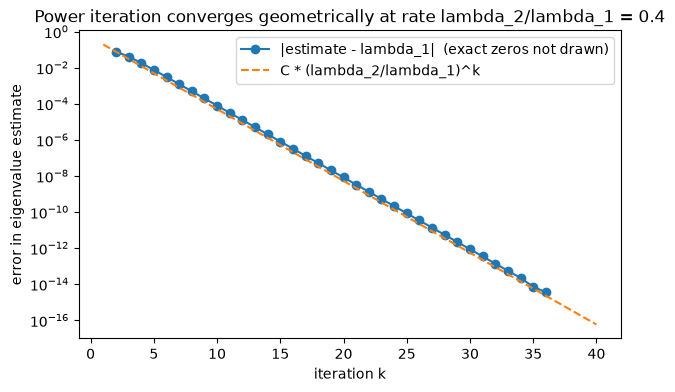

In [3]:
def power_iteration(A, n_iter=60, x0=None):
    x = np.ones(A.shape[0]) if x0 is None else np.asarray(x0, float)
    x = x / np.linalg.norm(x)
    estimates = []
    for _ in range(n_iter):
        y = A @ x
        x = y / np.linalg.norm(y)
        estimates.append(x @ A @ x)          # Rayleigh quotient
    return estimates[-1], x, np.array(estimates)

lam_est, v_est, hist = power_iteration(A, n_iter=40, x0=[1., 0.])
print("power iteration:  lambda_1 ~ %.10f,  v_1 ~ %s" % (lam_est, v_est))
print("np.linalg.eig:    lambda_1 = %.10f,  v_1 = %s" % (w[0], V[:, 0]))

err = np.abs(hist - w[0])
print("first three errors:", err[:3], " (the k = 1 estimate is exact)")
k = np.arange(1, len(hist) + 1)
plt.semilogy(k, np.where(err > 0, err, np.nan), "o-", label="|estimate - lambda_1|  (exact zeros not drawn)")
plt.semilogy(k, err[1] * (w[1] / w[0]) ** (k - 2), "--", label="C * (lambda_2/lambda_1)^k")
plt.title("Power iteration converges geometrically at rate lambda_2/lambda_1 = 0.4")
plt.xlabel("iteration k"); plt.ylabel("error in eigenvalue estimate"); plt.legend(); plt.show()

The error falls by a factor of $0.4 = \lambda_2/\lambda_1$ per step until it hits
floating-point precision near $10^{-16}$. (The very first estimate happens to be exact:
$Ae_1 = (4, 2) \propto (2, 1)$, whose Rayleigh quotient is exactly $5$, so the point at $k = 1$
is missing from the log plot.) If the two largest eigenvalues were close (ratio 0.99) the same
picture would need thousands of iterations — $0.99^k$ reaches $10^{-14}$ only at
$k \approx 3{,}200$. The *gap* controls the speed.

### A two-state Markov chain

A column-stochastic matrix $T$ (columns sum to one) has eigenvalue $1$, and its eigenvector —
scaled to sum to one — is the stationary distribution $\pi$. Repeatedly applying $T$ *is*
power iteration, and the second eigenvalue sets how fast the chain forgets its start.

In [4]:
T = np.array([[0.9, 0.5],     # column j = where brand j's customers go next month
              [0.1, 0.5]])
w_T, P = np.linalg.eig(T)
print("eigenvalues of T:", w_T.real)
pi = P[:, np.argmax(w_T.real)].real
pi = pi / pi.sum()
print("stationary distribution pi =", pi, "  (5/6, 1/6)")

x = np.array([0., 1.])                      # everyone starts with brand B
print("\nmonth   share A   share B   distance to pi")
for month in range(1, 11):
    x = T @ x
    print(f"{month:5d}   {x[0]:7.4f}   {x[1]:7.4f}   {np.abs(x - pi).sum():.2e}")

# A^k via the diagonalisation: P D^k P^-1  equals the direct matrix power
D = np.diag(w_T.real)
Tk_diag = P.real @ np.linalg.matrix_power(D, 10) @ np.linalg.inv(P.real)
print("\nmax |P D^10 P^-1 - T^10| =", np.abs(Tk_diag - np.linalg.matrix_power(T, 10)).max())
print("0.4^10 =", 0.4 ** 10, " -> the second eigenvalue is the speed of forgetting")

eigenvalues of T: [1.  0.4]
stationary distribution pi = [0.8333 0.1667]   (5/6, 1/6)

month   share A   share B   distance to pi
    1    0.5000    0.5000   6.67e-01
    2    0.7000    0.3000   2.67e-01
    3    0.7800    0.2200   1.07e-01
    4    0.8120    0.1880   4.27e-02
    5    0.8248    0.1752   1.71e-02
    6    0.8299    0.1701   6.83e-03
    7    0.8320    0.1680   2.73e-03
    8    0.8328    0.1672   1.09e-03
    9    0.8331    0.1669   4.37e-04
   10    0.8332    0.1668   1.75e-04

max |P D^10 P^-1 - T^10| = 2.220446049250313e-16
0.4^10 = 0.00010485760000000006  -> the second eigenvalue is the speed of forgetting


Both brands end at the shares $(5/6, 1/6)$ whatever the starting split, and the distance to
$\pi$ shrinks by exactly $0.4$ per month — the second eigenvalue.

### PageRank on a six-page web

PageRank is the stationary distribution of a random surfer who follows a random out-link
with probability $d = 0.85$ and jumps to a uniformly random page otherwise. With $M$ the
column-stochastic link matrix (a page with no out-links is treated as linking to every page),

$$G = d\,M + \frac{1-d}{n}\,\mathbf{1}\mathbf{1}^\top, \qquad \pi = G\pi .$$

Every entry of $G$ is positive, so the stationary vector is unique and $|\lambda_2| \le d$:
power iteration converges at least as fast as $0.85^k$, however large the web.

columns of G sum to one: True
converged in 53 iterations (bound 0.85^53 = 1.8e-04; actual rate |lambda_2| = 0.601, 0.601^53 = 1.9e-12)
PageRank: [0.3487 0.1795 0.3511 0.0446 0.0313 0.0446]  sum = 1.000000000000002
ranking (best first): [2 0 1 3 5 4]
max |power iteration - eig| = 1.580957587066223e-13
second-largest |eigenvalue| of G = 0.601 = d * |lambda_2(M)| = 0.85 * 0.7071  (<= d)


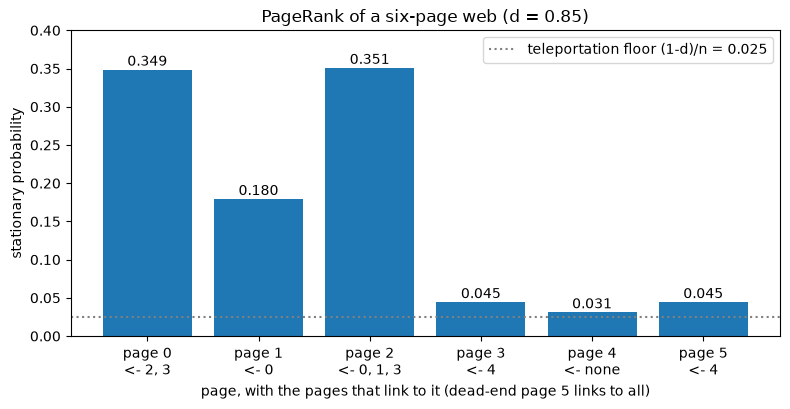

In [5]:
links = {0: [1, 2], 1: [2], 2: [0], 3: [0, 2], 4: [3, 5], 5: []}   # page 5 is a dead end
n = len(links)

M = np.zeros((n, n))                       # M[i, j] = prob. of going j -> i
for j, outs in links.items():
    if outs:
        M[outs, j] = 1.0 / len(outs)
    else:
        M[:, j] = 1.0 / n                  # dangling page: jump anywhere
d = 0.85
G = d * M + (1 - d) / n * np.ones((n, n))
print("columns of G sum to one:", np.allclose(G.sum(axis=0), 1))
w_G, V_G = np.linalg.eig(G)
lam2 = np.sort(np.abs(w_G))[-2]             # the actual convergence rate

x = np.ones(n) / n
for k in range(1, 200):
    x_new = G @ x
    if np.abs(x_new - x).sum() < 1e-12:
        break
    x = x_new
pagerank = x_new
print(f"converged in {k} iterations (bound {d:g}^{k} = {d**k:.1e};"
      f" actual rate |lambda_2| = {lam2:.3f}, {lam2:.3f}^{k} = {lam2**k:.1e})")
print("PageRank:", pagerank, " sum =", pagerank.sum())
print("ranking (best first):", np.argsort(-pagerank))

# cross-check with the eigenvector for eigenvalue 1
v1 = V_G[:, np.argmin(np.abs(w_G - 1))].real
print("max |power iteration - eig| =", np.abs(pagerank - v1 / v1.sum()).max())
lam2_M = np.sort(np.abs(np.linalg.eigvals(M)))[-2]
print("second-largest |eigenvalue| of G = %.3f = d * |lambda_2(M)| = %.2f * %.4f  (<= d)"
      % (lam2, d, lam2_M))

in_links = [[j for j, outs in links.items() if i in outs] for i in range(n)]
plt.figure(figsize=(8, 4.2))
plt.bar(range(n), pagerank, color="tab:blue")
for i, v in enumerate(pagerank):
    plt.text(i, v + 0.005, f"{v:.3f}", ha="center")
plt.axhline((1 - d) / n, color="gray", ls=":", label=f"teleportation floor (1-d)/n = {(1 - d) / n:.3f}")
plt.xticks(range(n), [f"page {i}\n<- {', '.join(map(str, l)) or 'none'}" for i, l in enumerate(in_links)])
plt.ylim(0, 0.4)
plt.title(f"PageRank of a six-page web (d = {d:g})")
plt.xlabel("page, with the pages that link to it (dead-end page 5 links to all)")
plt.ylabel("stationary probability"); plt.legend(); plt.tight_layout(); plt.show()

Pages 2 and 0 share the top with about 35 % each. Page 2 is linked to by three pages (0, 1
and 3). Page 0 is linked to by only two pages, 2 and the weak page 3 — but page 2 is the most
important page and sends page 0 its entire out-link weight. That is the whole idea of
PageRank: a link is worth what its source is worth. Pages 3, 4 and 5 are linked to from
nobody or only from the weak page 4, so they live mostly on the teleportation floor
$(1-d)/n = 0.025$ (the dotted line). Page 4, which nobody links to, sits a little above it at
0.031 because the dead-end page 5 spreads its rank over every page:
$0.025 + 0.85 \cdot 0.0446/6 = 0.031$.

How fast do the two chains of this section forget where they started, and how does the
damping factor $d$ reshape the ranking? Both questions are about eigenvalues.

PageRank at d = 0.99: [0.3963 0.1984 0.3964 0.0033 0.0022 0.0033]
pages 3 and 5 coincide for every d: True


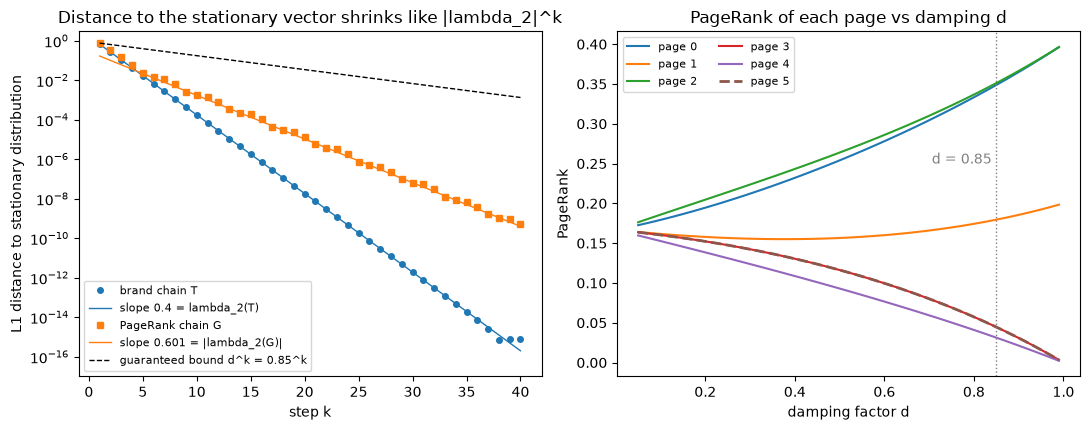

In [6]:
# convergence of the two chains, and PageRank as a function of the damping d
x_T, x_G = np.array([0., 1.]), np.eye(n)[5]          # brands: all start with B; surfer starts on page 5
dist_T, dist_G = [], []
for _ in range(40):
    x_T, x_G = T @ x_T, G @ x_G
    dist_T.append(np.abs(x_T - pi).sum()); dist_G.append(np.abs(x_G - pagerank).sum())
dist_T, dist_G = np.array(dist_T), np.array(dist_G)
ks_c = np.arange(1, 41)

ds = np.linspace(0.05, 0.99, 48)
pr_d = []
for d_ in ds:
    w_, V_ = np.linalg.eig(d_ * M + (1 - d_) / n * np.ones((n, n)))
    v_ = V_[:, np.argmax(w_.real)].real               # eigenvector for eigenvalue 1
    pr_d.append(v_ / v_.sum())
pr_d = np.array(pr_d)
print("PageRank at d = 0.99:", pr_d[-1])
print("pages 3 and 5 coincide for every d:", np.allclose(pr_d[:, 3], pr_d[:, 5]))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
ax = axes[0]
ax.semilogy(ks_c, dist_T, "o", ms=4, color="tab:blue", label="brand chain T")
ax.semilogy(ks_c, dist_T[0] * 0.4 ** (ks_c - 1), "-", color="tab:blue", lw=1, label="slope 0.4 = lambda_2(T)")
ax.semilogy(ks_c, dist_G, "s", ms=4, color="tab:orange", label="PageRank chain G")
ax.semilogy(ks_c, dist_G[9] * lam2 ** (ks_c - 10), "-", color="tab:orange", lw=1,
            label=f"slope {lam2:.3f} = |lambda_2(G)|")
ax.semilogy(ks_c, dist_G[0] * d ** (ks_c - 1), "k--", lw=1, label=f"guaranteed bound d^k = {d:g}^k")
ax.set_ylim(1e-17, 3)
ax.set_title("Distance to the stationary vector shrinks like |lambda_2|^k")
ax.set_xlabel("step k"); ax.set_ylabel("L1 distance to stationary distribution"); ax.legend(fontsize=8)
ax = axes[1]
for p in range(n):
    ax.plot(ds, pr_d[:, p], "--" if p == 5 else "-", lw=2 if p == 5 else 1.5, label=f"page {p}")
ax.axvline(d, color="gray", ls=":", lw=1)
ax.text(d - 0.01, 0.25, f"d = {d:g}", color="gray", ha="right")
ax.set_title("PageRank of each page vs damping d")
ax.set_xlabel("damping factor d"); ax.set_ylabel("PageRank"); ax.legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

**Notice that** each chain forgets its start at the rate of its own second eigenvalue: $0.4$
for the brands, and $|\lambda_2(G)| = 0.601$ for PageRank, which beats its guaranteed $0.85^k$
comfortably because $\lambda_2(G) = d\,\lambda_2(M)$ and here $|\lambda_2(M)| = 1/\sqrt2$. On the
right, as $d \to 1$ the loop 0→1→2→0 absorbs almost all the mass while pages 3, 4 and 5 sink
to $0.002$–$0.003$; as $d \to 0$ every page tends to the uniform $1/6$. Pages 3 and 5 coincide
for every $d$ (the dashed page-5 line is drawn on top of page 3's), because each gets exactly half of page 4's
links.

**Try it yourself:** set `d = 0.5` and then `d = 0.99` in the PageRank cell and compare the
iteration counts (53 at $d = 0.85$) with the prediction $\log(10^{-12}) / \log(d/\sqrt2)$: the
speed is set by $|\lambda_2(G)| = d/\sqrt2$, not by the worst-case bound $d^k$.

## 3. Symmetric matrices and the spectral theorem

For a symmetric matrix ($A = A^\top$) the eigenvalues are real and the eigenvectors can be
chosen orthonormal:

$$A = Q\Lambda Q^\top = \sum_i \lambda_i q_i q_i^\top, \qquad Q^\top Q = I .$$

In the eigen-coordinates $y = Q^\top x$ the quadratic form becomes a weighted sum of squares,
$x^\top A x = \sum_i \lambda_i y_i^2$, so $A$ is positive semidefinite exactly when every
$\lambda_i \ge 0$. The level set $x^\top A x = 1$ is an ellipse whose axes are the
eigenvectors and whose semi-axis lengths are $1/\sqrt{\lambda_i}$.

eigenvalues: [3. 1.]
Q (orthonormal eigenvectors as columns):
[[ 0.7071 -0.7071]
 [ 0.7071  0.7071]]
Q^T Q = I ? True
sum_i lambda_i q_i q_i^T reconstructs S ? True


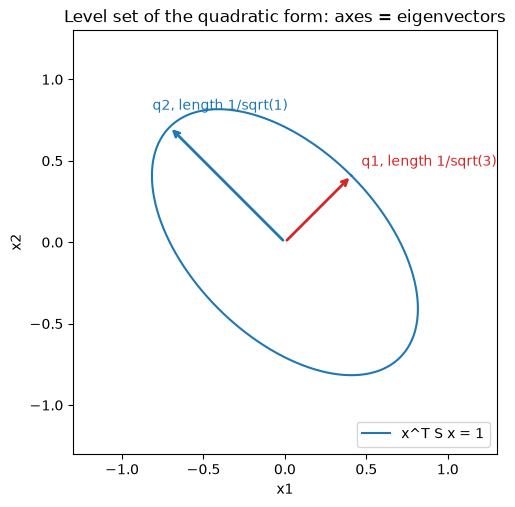

In [7]:
S = np.array([[2., 1.],
              [1., 2.]])
lam, Q = np.linalg.eigh(S)                  # eigh: symmetric input -> real, ascending
lam, Q = lam[::-1], Q[:, ::-1]              # descending
print("eigenvalues:", lam)
print("Q (orthonormal eigenvectors as columns):"); print(Q)
print("Q^T Q = I ?", np.allclose(Q.T @ Q, np.eye(2)))
recon = sum(lam[i] * np.outer(Q[:, i], Q[:, i]) for i in range(2))
print("sum_i lambda_i q_i q_i^T reconstructs S ?", np.allclose(recon, S))

# the ellipse x^T S x = 1 drawn via eigen-coordinates
theta = np.linspace(0, 2 * np.pi, 400)
y = np.vstack([np.cos(theta) / np.sqrt(lam[0]), np.sin(theta) / np.sqrt(lam[1])])
x = Q @ y
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot(x[0], x[1], label="x^T S x = 1")
for i, c in enumerate(["tab:red", "tab:blue"]):
    a = Q[:, i] / np.sqrt(lam[i])
    ax.annotate("", xy=a, xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=c, lw=2))
    ax.text(a[0] * 1.15, a[1] * 1.15, f"q{i+1}, length 1/sqrt({lam[i]:.0f})", color=c)
ax.set_aspect("equal"); ax.set_xlim(-1.3, 1.3); ax.set_ylim(-1.3, 1.3)
ax.set_title("Level set of the quadratic form: axes = eigenvectors")
ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.legend(loc="lower right"); plt.show()

The ellipse is short along $q_1 = (1,1)/\sqrt2$ (semi-axis $1/\sqrt3 \approx 0.58$): the form
grows fastest there, because $\lambda_1 = 3$ is the larger eigenvalue. Now the same facts
on a larger random symmetric matrix, and the two things we most often need in ML: a
covariance matrix is PSD, and the Rayleigh quotient is squeezed between $\lambda_{\min}$ and
$\lambda_{\max}$.

In [8]:
B = rng.normal(size=(5, 5))
S5 = B @ B.T                                # Gram matrices are symmetric PSD
lam5, Q5 = np.linalg.eigh(S5)
print("eigenvalues of B B^T:", lam5, "-> all >= 0, so PSD")
print("max |Q^T Q - I| = %.1e,   max |Q L Q^T - S| = %.1e"
      % (np.abs(Q5.T @ Q5 - np.eye(5)).max(), np.abs(Q5 @ np.diag(lam5) @ Q5.T - S5).max()))

# a covariance matrix of real-looking data is PSD too
data = rng.normal(size=(200, 4)) @ rng.normal(size=(4, 4))
C = np.cov(data, rowvar=False)
print("eigenvalues of a covariance matrix:", np.linalg.eigvalsh(C))

# Rayleigh quotient of 10,000 random directions never leaves [lambda_min, lambda_max]
X = rng.normal(size=(10000, 5))
rq = np.einsum("ij,jk,ik->i", X, S5, X) / np.einsum("ij,ij->i", X, X)
print("Rayleigh quotients: min %.4f, max %.4f;  eigenvalues: min %.4f, max %.4f"
      % (rq.min(), rq.max(), lam5.min(), lam5.max()))

eigenvalues of B B^T: [0.1755 0.5349 3.5257 4.5103 7.8622] -> all >= 0, so PSD
max |Q^T Q - I| = 4.4e-16,   max |Q L Q^T - S| = 2.7e-15
eigenvalues of a covariance matrix: [ 0.4016  0.9367  4.2698 16.5128]
Rayleigh quotients: min 0.2403, max 7.7341;  eigenvalues: min 0.1755, max 7.8622


The random Rayleigh quotients stay strictly inside $[\lambda_{\min}, \lambda_{\max}]$ and
never quite reach the ends — the extremes are attained only *at* the eigenvectors. To see
the whole landscape, walk a unit vector $u$ half-way around the circle (0° to 180°; $-u$ gives the same value as $u$) for the $2\times2$ matrix
$S$, and look at where the 10,000 random quotients of $S_5$ actually fall.

u^T S u: max 3.0000 at 45 deg, min 1.0000 at 135 deg
mean random Rayleigh quotient 3.327  vs  tr(S5)/5 = 3.322
share of random directions within 5% of the range from lambda_max: 0.23%


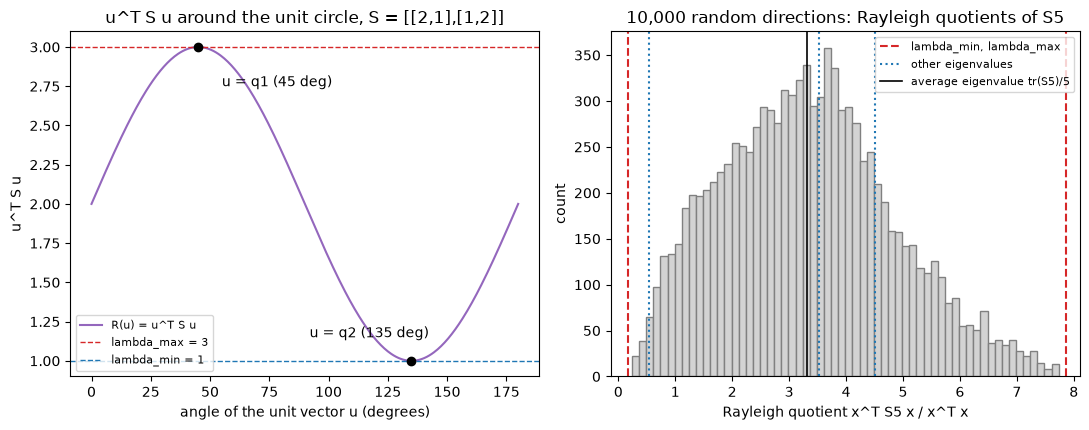

In [9]:
ang = np.linspace(0, 180, 361)
units = np.vstack([np.cos(np.radians(ang)), np.sin(np.radians(ang))])
R_ang = np.einsum("ij,ik,kj->j", units, S, units)        # u^T S u for every unit vector u
span = lam5.max() - lam5.min()
print("u^T S u: max %.4f at %g deg, min %.4f at %g deg"
      % (R_ang.max(), ang[np.argmax(R_ang)], R_ang.min(), ang[np.argmin(R_ang)]))
print("mean random Rayleigh quotient %.3f  vs  tr(S5)/5 = %.3f" % (rq.mean(), np.trace(S5) / 5))
print("share of random directions within 5%% of the range from lambda_max: %.2f%%"
      % (100 * np.mean(rq > lam5.max() - 0.05 * span)))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
ax = axes[0]
ax.plot(ang, R_ang, color="tab:purple", label="R(u) = u^T S u")
ax.axhline(lam[0], color="tab:red", ls="--", lw=1, label="lambda_max = 3")
ax.axhline(lam[1], color="tab:blue", ls="--", lw=1, label="lambda_min = 1")
ax.plot([45, 135], [3, 1], "ko")
ax.annotate("u = q1 (45 deg)", (45, 3), xytext=(55, 2.75))
ax.annotate("u = q2 (135 deg)", (135, 1), xytext=(92, 1.15))
ax.set_title("u^T S u around the unit circle, S = [[2,1],[1,2]]")
ax.set_xlabel("angle of the unit vector u (degrees)"); ax.set_ylabel("u^T S u")
ax.legend(loc="lower left", fontsize=8)
ax = axes[1]
ax.hist(rq, bins=60, color="lightgray", edgecolor="gray")
ax.axvline(lam5.min(), color="tab:red", ls="--", lw=1.5, label="lambda_min, lambda_max")
ax.axvline(lam5.max(), color="tab:red", ls="--", lw=1.5)
for l_ in lam5[1:-1]:
    ax.axvline(l_, color="tab:blue", ls=":", lw=1.5, label="other eigenvalues" if l_ == lam5[1] else None)
ax.axvline(np.trace(S5) / 5, color="k", lw=1.2, label="average eigenvalue tr(S5)/5")
ax.set_title("10,000 random directions: Rayleigh quotients of S5")
ax.set_xlabel("Rayleigh quotient x^T S5 x / x^T x"); ax.set_ylabel("count")
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Notice that** $u^\top S u = 2 + \sin 2\theta$ peaks at exactly $\lambda_{\max} = 3$ when $u$
points along $q_1$ (45°) and bottoms out at $\lambda_{\min} = 1$ along $q_2$ (135°): maximising
the Rayleigh quotient *is* finding the top eigenvector, and that "maximise $w^\top C w$ over
unit $w$" problem is exactly what PCA solves in Section 6. In five dimensions the random
directions pile up around the average eigenvalue $\operatorname{tr}(S_5)/5 \approx 3.3$, and
only about 0.2 % land within 5 % of $\lambda_{\max}$ — random search is a hopeless way to find
an eigenvector.

## 4. The singular value decomposition

Any $m\times n$ matrix factors as

$$A = U\Sigma V^\top = \sum_{i=1}^{r} \sigma_i u_i v_i^\top, \qquad A v_i = \sigma_i u_i ,$$

with orthonormal $u_i$ (left singular vectors), orthonormal $v_i$ (right singular vectors)
and $\sigma_1 \ge \sigma_2 \ge \dots > 0$. The $v_i$ are eigenvectors of $A^\top A$, the $u_i$
eigenvectors of $AA^\top$, and $\sigma_i^2$ are their shared eigenvalues. Geometrically:
rotate ($V^\top$), stretch along the axes ($\Sigma$), rotate ($U$) — so the unit circle
always becomes an ellipse with semi-axes $\sigma_i u_i$.

singular values: [6.7082 2.2361]    by hand: sqrt(45), sqrt(5) = 6.708203932499369 2.23606797749979
sqrt of eigenvalues of A^T A: [6.7082 2.2361]
eigenvalues of A itself:    [5. 3.] (different!)
sigma_1 * sigma_2 = 15.0000 = |det A| = 15.0000
U^T U = I: True   V^T V = I: True
U S V^T reconstructs A: True
A v1 = [-2.1213 -6.364 ]   sigma1 u1 = [-2.1213 -6.364 ]
A v2 = [-2.1213  0.7071]   sigma2 u2 = [-2.1213  0.7071]


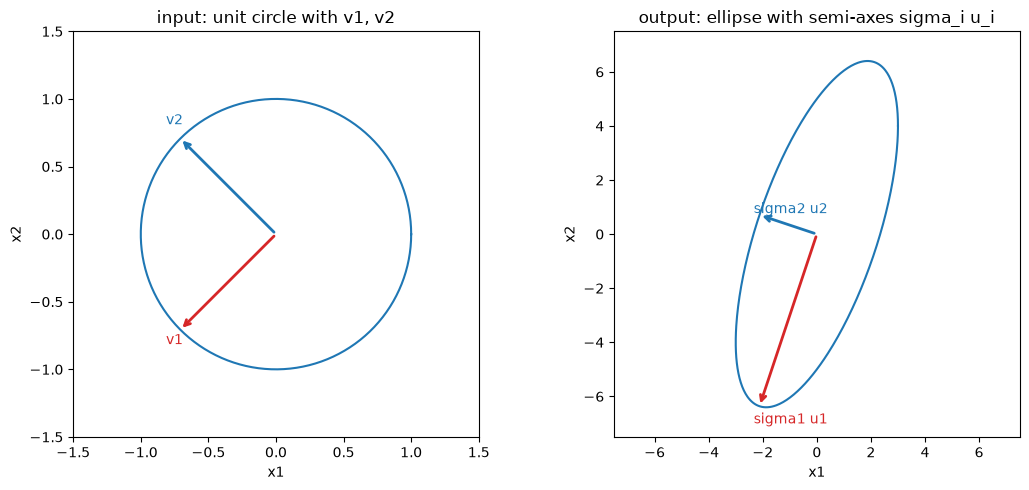

In [10]:
A2 = np.array([[3., 0.],
               [4., 5.]])
U, s, Vt = np.linalg.svd(A2)
print("singular values:", s, "   by hand: sqrt(45), sqrt(5) =", np.sqrt(45), np.sqrt(5))
print("sqrt of eigenvalues of A^T A:", np.sqrt(np.linalg.eigvalsh(A2.T @ A2)[::-1]))
print("eigenvalues of A itself:   ", np.sort(np.linalg.eigvals(A2).real)[::-1], "(different!)")
print("sigma_1 * sigma_2 = %.4f = |det A| = %.4f" % (s.prod(), abs(np.linalg.det(A2))))
print("U^T U = I:", np.allclose(U.T @ U, np.eye(2)), "  V^T V = I:", np.allclose(Vt @ Vt.T, np.eye(2)))
print("U S V^T reconstructs A:", np.allclose(U @ np.diag(s) @ Vt, A2))
for i in range(2):
    print(f"A v{i+1} = {A2 @ Vt[i]}   sigma{i+1} u{i+1} = {s[i] * U[:, i]}")

theta = np.linspace(0, 2 * np.pi, 400)
circle = np.vstack([np.cos(theta), np.sin(theta)])
image = A2 @ circle
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].plot(circle[0], circle[1]); axes[0].set_title("input: unit circle with v1, v2")
axes[1].plot(image[0], image[1]); axes[1].set_title("output: ellipse with semi-axes sigma_i u_i")
for i, c in enumerate(["tab:red", "tab:blue"]):
    axes[0].annotate("", xy=Vt[i], xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=c, lw=2))
    axes[0].text(Vt[i][0] * 1.15, Vt[i][1] * 1.15, f"v{i+1}", color=c)
    axes[1].annotate("", xy=s[i] * U[:, i], xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=c, lw=2))
    axes[1].text(s[i] * U[0, i] * 1.1, s[i] * U[1, i] * 1.1, f"sigma{i+1} u{i+1}", color=c)
for ax, lim in zip(axes, (1.5, 7.5)):
    ax.set_aspect("equal"); ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
    ax.set_xlabel("x1"); ax.set_ylabel("x2")
plt.tight_layout(); plt.show()

The circle's diameters along $v_1$ and $v_2$ map to the ellipse's axes: $v_1$ goes to
$\sigma_1 u_1$ (length 6.71) and $v_2$ to $\sigma_2 u_2$ (length 2.24). The eigenvalues of
this matrix, 5 and 3, are *not* its singular values — only the product agrees. Signs of the
singular vectors are arbitrary (NumPy may flip a pair), which never changes the picture.

### Singular values reveal rank — even under noise

A matrix built from three rank-one pieces has exactly three non-zero singular values. Add
noise and the zeros become small-but-non-zero: the *scree plot* shows a cliff after the true
rank, which is how one decides how many components to keep.

rank of L: 3    rank of L + noise: 40
first 6 singular values, clean: [55.6478 37.7355 34.4255  0.      0.      0.    ]
first 6 singular values, noisy: [55.8946 37.8997 34.7364  3.9336  3.5492  3.4495]


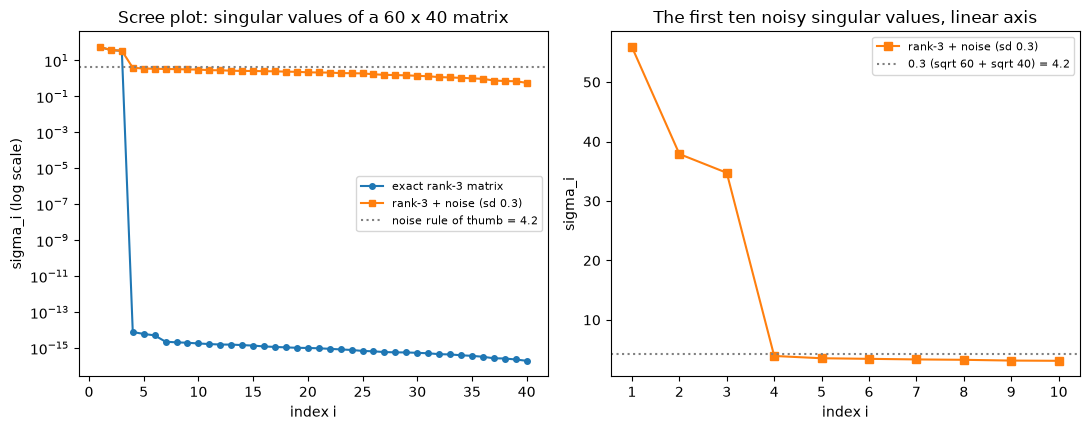

In [11]:
m, n_cols, r_true = 60, 40, 3
L = rng.normal(size=(m, r_true)) @ rng.normal(size=(r_true, n_cols))   # exact rank 3
tau = 0.3                                              # noise standard deviation
noise = tau * rng.normal(size=(m, n_cols))
s_clean = np.linalg.svd(L, compute_uv=False)
s_noisy = np.linalg.svd(L + noise, compute_uv=False)
print("rank of L:", np.linalg.matrix_rank(L), "   rank of L + noise:", np.linalg.matrix_rank(L + noise))
print("first 6 singular values, clean:", s_clean[:6])
print("first 6 singular values, noisy:", s_noisy[:6])

noise_level = tau * (np.sqrt(m) + np.sqrt(n_cols))     # largest singular value of pure noise, roughly
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
ax = axes[0]
ax.semilogy(np.arange(1, 41), s_clean + 1e-16, "o-", ms=4, label="exact rank-3 matrix")
ax.semilogy(np.arange(1, 41), s_noisy, "s-", ms=4, label=f"rank-3 + noise (sd {tau:g})")
ax.axhline(noise_level, color="gray", ls=":", label=f"noise rule of thumb = {noise_level:.1f}")
ax.set_title("Scree plot: singular values of a 60 x 40 matrix")
ax.set_xlabel("index i"); ax.set_ylabel("sigma_i (log scale)"); ax.legend(fontsize=8)
ax = axes[1]
ax.plot(np.arange(1, 11), s_noisy[:10], "s-", color="tab:orange", label=f"rank-3 + noise (sd {tau:g})")
ax.axhline(noise_level, color="gray", ls=":", label="%g (sqrt 60 + sqrt 40) = %.1f" % (tau, noise_level))
ax.set_xticks(range(1, 11))
ax.set_title("The first ten noisy singular values, linear axis")
ax.set_xlabel("index i"); ax.set_ylabel("sigma_i"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

The clean matrix has three large singular values and the rest are at the level of rounding
error ($10^{-14}$ — `matrix_rank` correctly says 3); on the log axis those rounding-level
values stretch the picture over many decades. With noise, every singular value is non-zero
(`matrix_rank` now says 40), but there is still a cliff: $\sigma_3 \approx 35$ against
$\sigma_4 \approx 4$, plain to see on the linear axis on the right. The largest singular value
of a pure-noise matrix with entries of standard deviation $\tau$ is roughly
$\tau(\sqrt{m} + \sqrt{n})$ — here $0.3\,(\sqrt{60} + \sqrt{40}) \approx 4.2$, the dotted
line — a useful rule of thumb for deciding whether a singular value is "signal": three values
stand far above it, and the rest start just below it ($\sigma_4 \approx 3.9$) and decline
slowly to about $0.6$, with no second cliff.

**Try it yourself:** raise the noise standard deviation `tau` to `1.5`. At what level does the
cliff disappear, so that the true rank is no longer readable from the plot?

## 5. Low-rank approximation — image compression

Keeping the $k$ largest terms of the SVD gives $A_k = \sum_{i \le k} \sigma_i u_i v_i^\top$,
and the **Eckart–Young theorem** says no rank-$k$ matrix is closer:

$$\|A - A_k\|_F = \sqrt{\textstyle\sum_{i>k}\sigma_i^2}, \qquad \|A - A_k\|_2 = \sigma_{k+1} .$$

Storing $A_k$ costs $k(m + n + 1)$ numbers instead of $mn$. We compress a synthetic $64\times64$
image and check the theorem's error formula against the directly measured error.

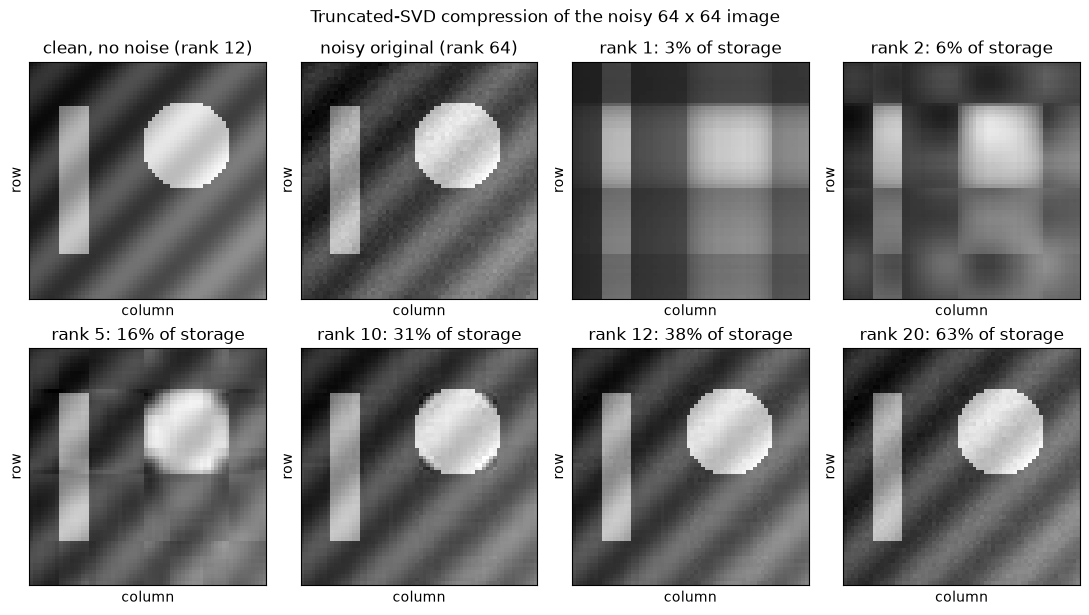

In [12]:
yy, xx = np.mgrid[0:64, 0:64]
img = 0.3 * xx / 63 + 0.2 * yy / 63                       # smooth gradient (rank 2)
img = img + 0.6 * (((xx - 42) ** 2 + (yy - 22) ** 2) < 12 ** 2)   # a disc
img[12:52, 8:16] += 0.5                                    # a vertical bar
img = img + 0.12 * np.sin((xx + yy) / 4.0)                 # diagonal stripes (rank 2)
img_clean = img.copy()                                     # kept to measure denoising later
img = img + 0.02 * rng.normal(size=img.shape)              # a little sensor noise

U, s, Vt = np.linalg.svd(img)
def rank_k(U, s, Vt, k):
    return (U[:, :k] * s[:k]) @ Vt[:k]

ks = [1, 2, 5, 10, 12, 20]
fig, axes = plt.subplots(2, 4, figsize=(11, 6.2))
axes = axes.ravel()
axes[0].imshow(img_clean, cmap="gray", vmin=img.min(), vmax=img.max())
axes[0].set_title("clean, no noise (rank %d)" % np.linalg.matrix_rank(img_clean))
axes[1].imshow(img, cmap="gray", vmin=img.min(), vmax=img.max())
axes[1].set_title("noisy original (rank %d)" % np.linalg.matrix_rank(img))
for ax, k in zip(axes[2:], ks):
    ax.imshow(rank_k(U, s, Vt, k), cmap="gray", vmin=img.min(), vmax=img.max())
    ax.set_title(f"rank {k}: {k * (64 + 64 + 1) / 64**2:.0%} of storage")
for ax in axes:
    ax.set_xlabel("column"); ax.set_ylabel("row"); ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Truncated-SVD compression of the noisy 64 x 64 image"); plt.tight_layout(); plt.show()

max |measured - Eckart-Young formula| = 1.05983394213252e-13
k =  1: relative Frobenius error 0.363,  energy captured 86.8%
k =  2: relative Frobenius error 0.289,  energy captured 91.6%
k =  5: relative Frobenius error 0.117,  energy captured 98.6%
k = 10: relative Frobenius error 0.051,  energy captured 99.7%
k = 12: relative Frobenius error 0.037,  energy captured 99.9%
k = 20: relative Frobenius error 0.028,  energy captured 99.9%


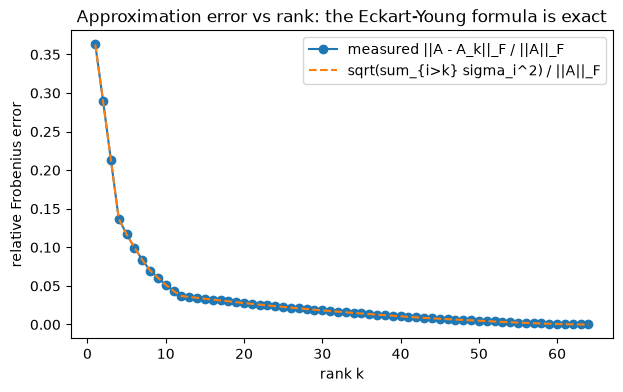

In [13]:
total_energy = (s ** 2).sum()
ks_all = np.arange(1, 65)
measured = np.array([np.linalg.norm(img - rank_k(U, s, Vt, k)) for k in ks_all])
eckart_young = np.sqrt(np.cumsum(s[::-1] ** 2)[::-1][1:].tolist() + [0.0])   # sqrt(sum_{i>k} sigma_i^2)
print("max |measured - Eckart-Young formula| =", np.abs(measured - eckart_young).max())
for k in ks:
    print(f"k = {k:2d}: relative Frobenius error {measured[k-1] / np.linalg.norm(img):.3f},"
          f"  energy captured {(s[:k]**2).sum() / total_energy:.1%}")

plt.plot(ks_all, measured / np.linalg.norm(img), "o-", label="measured ||A - A_k||_F / ||A||_F")
plt.plot(ks_all, eckart_young / np.linalg.norm(img), "--", label="sqrt(sum_{i>k} sigma_i^2) / ||A||_F")
plt.title("Approximation error vs rank: the Eckart-Young formula is exact")
plt.xlabel("rank k"); plt.ylabel("relative Frobenius error"); plt.legend(); plt.show()

Rank 1 is a blur of row and column averages; by rank 5 every shape is recognisable; rank 10
already shows every shape (with faint dark notches at the four diagonal corners of the disc's rim) at 31 % of the
storage, and rank 12 looks like the clean picture at 38 %. The measured error curve sits
exactly on the Eckart–Young formula — the theorem is not an approximation. The clean image
has rank 12 (a gradient of rank 2, stripes of rank 2, a disc of rank 7, because its rows take
seven different widths, and a bar of rank 1), so the singular values beyond the twelfth are
pure sensor noise; the error curve bends at $k \approx 12$ and then declines slowly. That
suggests truncating there actually *denoises* the picture. We kept the clean image, so we can
measure it.

singular values above the noise level 0.32: 12   (sigma_12 = 0.637, sigma_13 = 0.259)
relative error to the CLEAN image: k = 10: 0.0435,  k = 12 (best): 0.0276,  k = 20: 0.0367,  noisy image itself: 0.0460


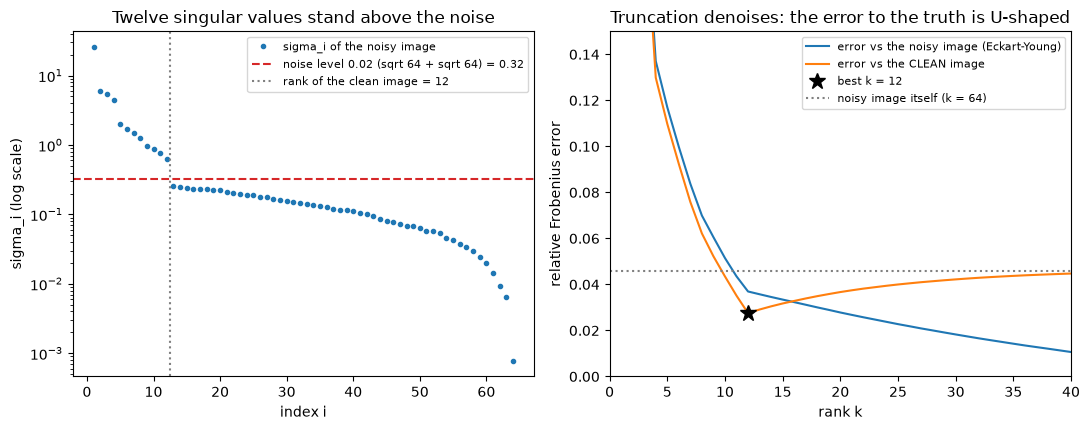

In [14]:
err_noisy = measured / np.linalg.norm(img)
err_clean = np.array([np.linalg.norm(img_clean - rank_k(U, s, Vt, k)) for k in ks_all]) / np.linalg.norm(img_clean)
floor = 0.02 * (np.sqrt(64) + np.sqrt(64))          # tau (sqrt m + sqrt n): top singular value of pure noise
k_best = int(ks_all[np.argmin(err_clean)])
print("singular values above the noise level %.2f: %d   (sigma_12 = %.3f, sigma_13 = %.3f)"
      % (floor, (s > floor).sum(), s[11], s[12]))
print("relative error to the CLEAN image: k = 10: %.4f,  k = %d (best): %.4f,  k = 20: %.4f,"
      "  noisy image itself: %.4f" % (err_clean[9], k_best, err_clean.min(), err_clean[19], err_clean[-1]))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
ax = axes[0]
ax.semilogy(ks_all, s, "o", ms=3, label="sigma_i of the noisy image")
ax.axhline(floor, color="tab:red", ls="--", label="noise level 0.02 (sqrt 64 + sqrt 64) = 0.32")
ax.axvline(12.5, color="gray", ls=":", label="rank of the clean image = 12")
ax.set_title("Twelve singular values stand above the noise")
ax.set_xlabel("index i"); ax.set_ylabel("sigma_i (log scale)"); ax.legend(fontsize=8)
ax = axes[1]
ax.plot(ks_all, err_noisy, "-", label="error vs the noisy image (Eckart-Young)")
ax.plot(ks_all, err_clean, "-", label="error vs the CLEAN image")
ax.plot(k_best, err_clean.min(), "k*", ms=12, label=f"best k = {k_best}")
ax.axhline(err_clean[-1], color="gray", ls=":", label="noisy image itself (k = 64)")
ax.set_xlim(0, 40); ax.set_ylim(0, 0.15)
ax.set_title("Truncation denoises: the error to the truth is U-shaped")
ax.set_xlabel("rank k"); ax.set_ylabel("relative Frobenius error"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Notice that** exactly twelve singular values stand above the noise level $0.32$, matching
the clean rank, and that the error to the *clean* image is smallest at $k = 12$ (2.8 %), well
below the 4.6 % of the noisy original itself: every extra component adds back more noise than
signal. Eckart–Young measures the distance to the data you have; denoising needs the distance
to the data you wish you had.

## 6. PCA from scratch — and against scikit-learn

For a centred data matrix $X_c$ ($n$ rows, $d$ features), the principal components are the
eigenvectors of the covariance $C = X_c^\top X_c/(n-1)$, or equivalently the right singular
vectors of $X_c$ with $\lambda_i = \sigma_i^2/(n-1)$. The explained variance ratio is
$\lambda_i / \sum_j \lambda_j$; scores are $Z = X_c V_k$; the reconstruction is
$\hat X = Z V_k^\top + \mu$.

We do all of it on the Iris data (150 flowers, 4 measurements in cm) both ways, then call
`sklearn.decomposition.PCA` and confirm it agrees to machine precision.

explained variance ratio, covariance route: [0.9246 0.0531 0.0171 0.0052]
explained variance ratio, SVD route:        [0.9246 0.0531 0.0171 0.0052]
explained variance ratio, sklearn:          [0.9246 0.0531 0.0171 0.0052]
components agree up to sign (cov vs sklearn): True
components agree up to sign (SVD vs sklearn): True
first component (loadings on sepal len, sepal wid, petal len, petal wid): [ 0.3614 -0.0845  0.8567  0.3583]

k = 2: variance explained 97.77%
total squared reconstruction error 15.2046  =  (n-1) * sum of dropped eigenvalues 15.2046


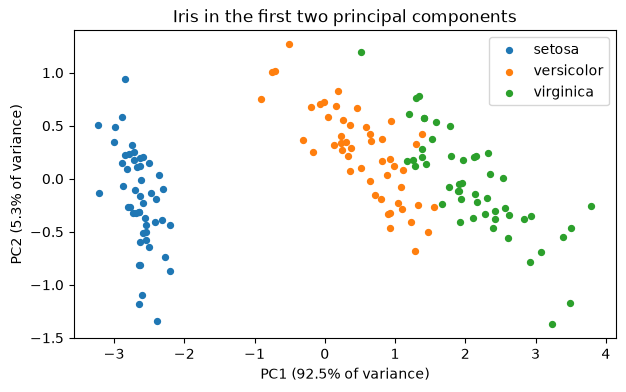

In [15]:
from sklearn.datasets import load_iris
from sklearn.decomposition import PCA

iris = load_iris()
X, y_lab = iris.data, iris.target
n_samples, d = X.shape
mu = X.mean(axis=0)
Xc = X - mu

# route 1: eigenvectors of the covariance matrix
C = Xc.T @ Xc / (n_samples - 1)
lam, W = np.linalg.eigh(C)
lam, W = lam[::-1], W[:, ::-1]
evr_cov = lam / lam.sum()

# route 2: SVD of the centred data (never forms C)
U, s, Vt = np.linalg.svd(Xc, full_matrices=False)
lam_svd = s ** 2 / (n_samples - 1)
evr_svd = lam_svd / lam_svd.sum()

# route 3: scikit-learn
pca = PCA().fit(X)

print("explained variance ratio, covariance route:", evr_cov)
print("explained variance ratio, SVD route:       ", evr_svd)
print("explained variance ratio, sklearn:         ", pca.explained_variance_ratio_)
print("components agree up to sign (cov vs sklearn):", np.allclose(np.abs(W.T), np.abs(pca.components_)))
print("components agree up to sign (SVD vs sklearn):", np.allclose(np.abs(Vt), np.abs(pca.components_)))
print("first component (loadings on sepal len, sepal wid, petal len, petal wid):", Vt[0])

k = 2
Z = Xc @ Vt[:k].T                         # scores = new coordinates
X_hat = Z @ Vt[:k] + mu                   # rank-2 reconstruction
resid = ((X - X_hat) ** 2).sum()
print(f"\nk = {k}: variance explained {evr_svd[:k].sum():.2%}")
print("total squared reconstruction error %.4f  =  (n-1) * sum of dropped eigenvalues %.4f"
      % (resid, (n_samples - 1) * lam_svd[k:].sum()))

for cls, name in enumerate(iris.target_names):
    plt.scatter(Z[y_lab == cls, 0], Z[y_lab == cls, 1], s=18, label=name)
plt.title("Iris in the first two principal components")
plt.xlabel(f"PC1 ({evr_svd[0]:.1%} of variance)"); plt.ylabel(f"PC2 ({evr_svd[1]:.1%} of variance)")
plt.legend(); plt.show()

All three routes give the same numbers: PC1 carries 92.5 % of the variance and PC2 another
5.3 %, so the 2-D picture keeps 97.8 % of the spread of the 4-D cloud. Three of the four
loadings of PC1 share a sign (sepal width has a small opposite loading, $-0.08$) and the
largest by far is petal length ($0.86$): the first component is mostly "petal size", the
measurement that varies most. The three species separate well on PC1 — but remember PCA never saw
the labels; it found the direction of largest *variance*, which here happens to coincide with
species.

### What happens without scaling

PCA is not scale-invariant. Suppose one lab recorded petal length in micrometres
(a factor 10,000 larger) rather than centimetres.

In [16]:
X_bad = X.copy()
X_bad[:, 2] *= 10_000                       # petal length now in micrometres
evr_bad = PCA().fit(X_bad).explained_variance_ratio_
comp_bad = PCA().fit(X_bad).components_[0]
print("explained variance ratio with one feature in micrometres:", evr_bad)
print("first component:", comp_bad, "-> it is just the petal-length axis")

X_std = (X_bad - X_bad.mean(axis=0)) / X_bad.std(axis=0, ddof=1)   # standardise every column
evr_std = PCA().fit(X_std).explained_variance_ratio_
print("\nafter standardising each column:", evr_std)
print("first component:", PCA().fit(X_std).components_[0])
print("(the same as standardising the original cm data:", np.allclose(
      evr_std, PCA().fit((X - mu) / X.std(axis=0, ddof=1)).explained_variance_ratio_), ")")

explained variance ratio with one feature in micrometres: [1. 0. 0. 0.]
first component: [ 0. -0.  1.  0.] -> it is just the petal-length axis

after standardising each column: [0.7296 0.2285 0.0367 0.0052]
first component: [ 0.5211 -0.2693  0.5804  0.5649]
(the same as standardising the original cm data: True )


With one badly scaled feature, "PC1 explains 99.9999999 % of the variance" — and it is just
that feature. Standardising restores a sensible split (73 %, 23 %, ...) that does not depend
on the units anyone chose. When features have different units, standardise first. Here are
the loadings and the variance shares of all three versions side by side.

cm (raw)                     PC1 loadings [ 0.36 -0.08  0.86  0.36]   variance ratios [0.925 0.053 0.017 0.005]
petal length in micrometres  PC1 loadings [ 0. -0.  1.  0.]   variance ratios [1. 0. 0. 0.]
standardised                 PC1 loadings [ 0.52 -0.27  0.58  0.56]   variance ratios [0.73  0.229 0.037 0.005]


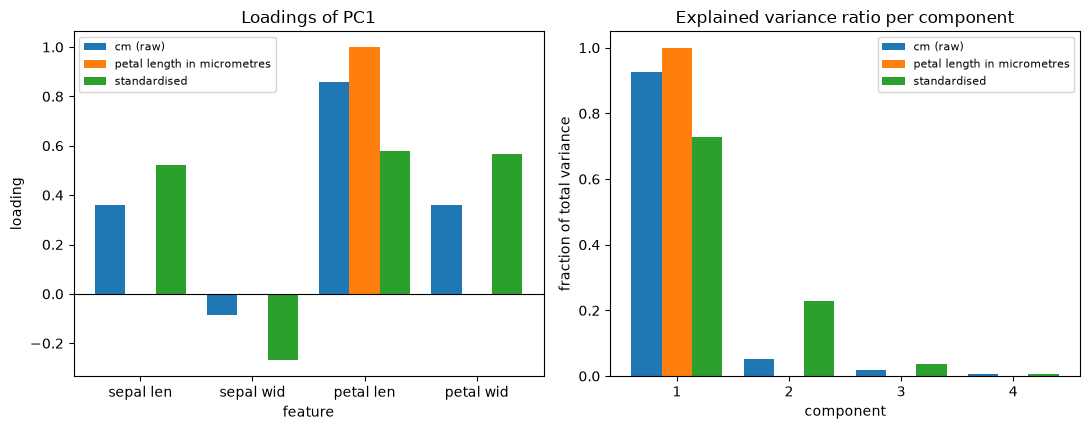

In [17]:
versions = {"cm (raw)": X, "petal length in micrometres": X_bad, "standardised": X_std}
feat = ["sepal len", "sepal wid", "petal len", "petal wid"]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
wbar = 0.27
for j, (name, data_) in enumerate(versions.items()):
    p_ = PCA().fit(data_)
    c_ = p_.components_[0] * np.sign(p_.components_[0][2])   # fix the arbitrary sign: petal length > 0
    print(f"{name:28s} PC1 loadings {np.round(c_, 2)}   variance ratios {np.round(p_.explained_variance_ratio_, 3)}")
    axes[0].bar(np.arange(4) + (j - 1) * wbar, c_, wbar, label=name)
    axes[1].bar(np.arange(1, 5) + (j - 1) * wbar, p_.explained_variance_ratio_, wbar, label=name)
axes[0].axhline(0, color="k", lw=0.8)
axes[0].set_xticks(range(4)); axes[0].set_xticklabels(feat)
axes[0].set_title("Loadings of PC1"); axes[0].set_xlabel("feature"); axes[0].set_ylabel("loading")
axes[0].legend(fontsize=8)
axes[1].set_xticks(range(1, 5))
axes[1].set_title("Explained variance ratio per component")
axes[1].set_xlabel("component"); axes[1].set_ylabel("fraction of total variance"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Notice that** in micrometres PC1 is the petal-length axis alone (loading 1, everything else
0) and takes all the variance. After standardising, PC1 weighs sepal length, petal length and
petal width almost equally (0.52–0.58) and PC2 earns a real 23 % share. Sepal width has the
opposite sign to the other three in every version (in micrometres its loading is merely too
small to see).

**Try it yourself:** compute the cumulative explained variance `np.cumsum(evr_std)` and find
the smallest $k$ that captures 99 %. Then repeat for `load_wine()` (13 features) — how many
components does it need?

## 7. The pseudo-inverse and least squares via the SVD

$$A^{+} = V\Sigma^{+}U^\top, \qquad \Sigma^{+}_{ii} = 1/\sigma_i \ \text{ if } \sigma_i > 0,\ \text{ else } 0,
\qquad x^{+} = A^{+}b = \sum_{\sigma_i>0}\frac{u_i^\top b}{\sigma_i}\,v_i .$$

$x^{+}$ minimises $\|Ax - b\|$ and, among all minimisers, has the smallest norm. It exists
even when $A^\top A$ is singular — the case the normal equations cannot handle. We build it
for a calibration problem with two perfectly collinear sensors (the same temperature in
Celsius and Fahrenheit).

In [18]:
def pinv_svd(A, rcond=1e-12):
    U, s, Vt = np.linalg.svd(A, full_matrices=False)
    s_plus = np.where(s > rcond * s.max(), 1.0 / np.where(s > 0, s, 1.0), 0.0)
    return Vt.T @ (s_plus[:, None] * U.T)

celsius = np.array([20., 25., 30., 35., 40., 45.])
fahrenheit = 1.8 * celsius + 32                       # exactly collinear with [1, celsius]
hardness = 50 + 0.8 * celsius + rng.normal(0, 0.5, size=6)
Xd = np.column_stack([np.ones(6), celsius, fahrenheit])  # design matrix, rank 2

print("singular values of the design matrix:", np.linalg.svd(Xd, compute_uv=False))
print("rank:", np.linalg.matrix_rank(Xd), " -> X^T X is singular, cond =", np.linalg.cond(Xd.T @ Xd))

coef_min = pinv_svd(Xd) @ hardness
print("\nour pinv agrees with np.linalg.pinv:", np.allclose(pinv_svd(Xd), np.linalg.pinv(Xd)))
print("lstsq gives the same coefficients:", np.allclose(coef_min, np.linalg.lstsq(Xd, hardness, rcond=None)[0]))
print("minimum-norm coefficients [intercept, C, F]:", coef_min, " norm = %.4f" % np.linalg.norm(coef_min))

# any null-space direction gives the SAME fit but a LONGER coefficient vector
null_dir = np.array([32., 1.8, -1.])      # 32*1 + 1.8*C - F = 0 for every row
print("X @ null_dir = 0 ?", np.allclose(Xd @ null_dir, 0))
coef_other = coef_min + 0.5 * null_dir
print("same predictions ?", np.allclose(Xd @ coef_other, Xd @ coef_min),
      "  norm = %.4f (larger)" % np.linalg.norm(coef_other))
print("residual of the fit: %.4f" % np.linalg.norm(Xd @ coef_min - hardness))

singular values of the design matrix: [239.3593   6.8638   0.    ]
rank: 2  -> X^T X is singular, cond = 5.2917237540408877e+17

our pinv agrees with np.linalg.pinv: True
lstsq gives the same coefficients: True
minimum-norm coefficients [intercept, C, F]: [ 0.1589 -1.9673  1.5445]  norm = 2.5062
X @ null_dir = 0 ? True
same predictions ? True   norm = 16.2278 (larger)
residual of the fit: 1.8205


The third singular value is zero (up to rounding), so $X^\top X$ cannot be inverted — but
`pinv_svd` simply skips that direction and returns the shortest coefficient vector that fits
the data. Adding any multiple of the null-space direction $(32, 1.8, -1)$ leaves every
prediction unchanged and only makes the coefficients longer. That is why `np.linalg.lstsq`
and `sklearn.linear_model.LinearRegression` are SVD-based. Let's walk along that null-space
direction and watch the fit and the length.

coef_min . null_dir = -5.3e-15  (orthogonal)
residual along the whole path: min 1.8205, max 1.8205
norm at t = 0: 2.5062,  t = 0.5: 16.2278,  ||null_dir|| = 32.07


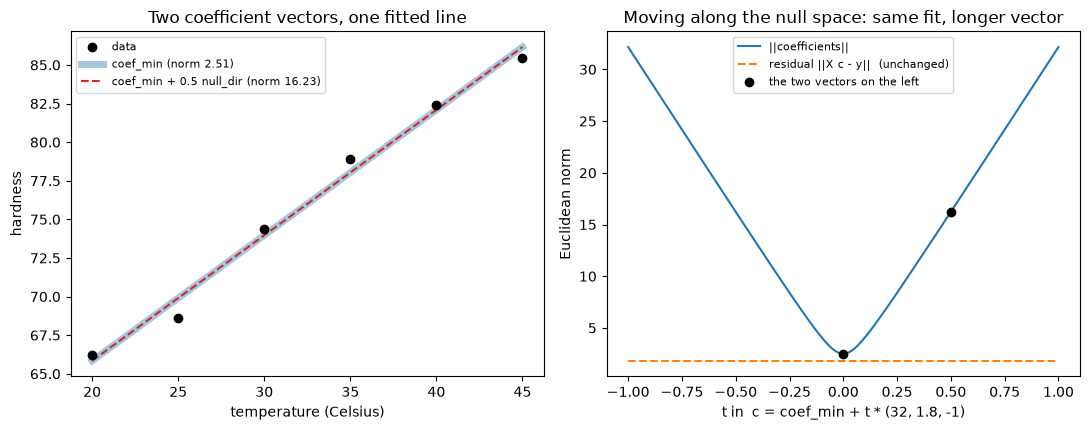

In [19]:
ts_ = np.linspace(-1, 1, 201)
norms_ = np.array([np.linalg.norm(coef_min + t_ * null_dir) for t_ in ts_])
resid_ = np.array([np.linalg.norm(Xd @ (coef_min + t_ * null_dir) - hardness) for t_ in ts_])
print("coef_min . null_dir = %.1e  (orthogonal)" % (coef_min @ null_dir))
print("residual along the whole path: min %.4f, max %.4f" % (resid_.min(), resid_.max()))
print("norm at t = 0: %.4f,  t = 0.5: %.4f,  ||null_dir|| = %.2f"
      % (np.linalg.norm(coef_min), np.linalg.norm(coef_other), np.linalg.norm(null_dir)))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
ax = axes[0]
ax.scatter(celsius, hardness, color="k", zorder=3, label="data")
ax.plot(celsius, Xd @ coef_min, "-", lw=5, alpha=0.4, label=f"coef_min (norm {np.linalg.norm(coef_min):.2f})")
ax.plot(celsius, Xd @ coef_other, "--", color="tab:red",
        label=f"coef_min + 0.5 null_dir (norm {np.linalg.norm(coef_other):.2f})")
ax.set_title("Two coefficient vectors, one fitted line")
ax.set_xlabel("temperature (Celsius)"); ax.set_ylabel("hardness"); ax.legend(fontsize=8)
ax = axes[1]
ax.plot(ts_, norms_, label="||coefficients||")
ax.plot(ts_, resid_, "--", label="residual ||X c - y||  (unchanged)")
ax.plot([0, 0.5], [np.linalg.norm(coef_min), np.linalg.norm(coef_other)], "ko",
        label="the two vectors on the left")
ax.set_title("Moving along the null space: same fit, longer vector")
ax.set_xlabel("t in  c = coef_min + t * (32, 1.8, -1)"); ax.set_ylabel("Euclidean norm")
ax.legend(fontsize=8, loc="upper center")
plt.tight_layout(); plt.show()

**Notice that** the two fitted lines are indistinguishable and the residual stays at $1.82$
for every $t$, while the coefficient norm grows like $\sqrt{2.51^2 + t^2 \cdot 32.07^2}$:
`coef_min` is orthogonal to the null-space direction, so Pythagoras puts the pseudo-inverse
solution at the bottom of the valley.

**Ridge regression** softens the hard cut-off: instead of $1/\sigma_i$ (or $0$) it uses the
filter $\sigma_i/(\sigma_i^2 + \lambda)$, which leaves large singular values alone and
shrinks small ones towards zero.

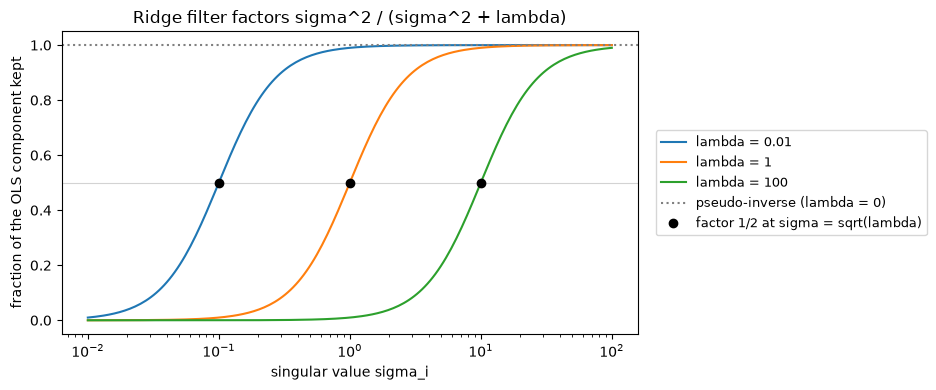

A direction with sigma = 0.1 and lambda = 1 keeps only 1.0% of its OLS coefficient.


In [20]:
sig = np.logspace(-2, 2, 200)
plt.figure(figsize=(9.5, 4))
plt.axhline(0.5, color="lightgray", lw=0.8)
lams_ridge = [0.01, 1.0, 100.0]
for lam_ridge in lams_ridge:
    plt.semilogx(sig, sig ** 2 / (sig ** 2 + lam_ridge), label=f"lambda = {lam_ridge:g}")
plt.axhline(1.0, color="gray", ls=":", label="pseudo-inverse (lambda = 0)")
plt.plot(np.sqrt(lams_ridge), [0.5] * 3, "ko", label="factor 1/2 at sigma = sqrt(lambda)")
plt.title("Ridge filter factors sigma^2 / (sigma^2 + lambda)")
plt.xlabel("singular value sigma_i"); plt.ylabel("fraction of the OLS component kept")
plt.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=9); plt.tight_layout(); plt.show()
print("A direction with sigma = 0.1 and lambda = 1 keeps only %.1f%% of its OLS coefficient."
      % (100 * 0.1 ** 2 / (0.1 ** 2 + 1)))

Directions with $\sigma_i^2 \gg \lambda$ pass unchanged; directions with $\sigma_i^2 \ll
\lambda$ — the ones the data barely constrain and that amplify noise most — are nearly
removed. Each curve passes $1/2$ exactly at $\sigma = \sqrt\lambda$ (the black dots), so
$\sqrt\lambda$ is where ridge draws its soft line. Module 13 derives this and shows why it
reduces variance.

## 8. Condition number and numerical stability

$$\kappa(A) = \frac{\sigma_{\max}}{\sigma_{\min}}, \qquad
\frac{\|\delta x\|}{\|x\|} \le \kappa(A)\,\frac{\|\delta b\|}{\|b\|}.$$

We manufacture matrices with a prescribed $\kappa$ (random orthogonal $U$, $V$ and chosen
singular values), perturb $b$ by one part in $10^8$, and measure how much the solution of
$Ax = b$ moves — for random perturbations and for the worst-case direction.

kappa =   1e+00:  np.linalg.cond = 1.00e+00,  amplification random (median of 30) 1.00e+00,  worst case 1.00e+00
kappa =   1e+01:  np.linalg.cond = 1.00e+01,  amplification random (median of 30) 2.18e+00,  worst case 1.00e+01
kappa =   1e+02:  np.linalg.cond = 1.00e+02,  amplification random (median of 30) 1.33e+01,  worst case 1.00e+02
kappa =   1e+03:  np.linalg.cond = 1.00e+03,  amplification random (median of 30) 9.51e+01,  worst case 1.00e+03
kappa =   1e+04:  np.linalg.cond = 1.00e+04,  amplification random (median of 30) 9.18e+02,  worst case 1.00e+04
kappa =   1e+05:  np.linalg.cond = 1.00e+05,  amplification random (median of 30) 4.93e+03,  worst case 1.00e+05
kappa =   1e+06:  np.linalg.cond = 1.00e+06,  amplification random (median of 30) 7.78e+04,  worst case 1.00e+06
kappa =   1e+07:  np.linalg.cond = 1.00e+07,  amplification random (median of 30) 4.78e+05,  worst case 1.00e+07
kappa =   1e+08:  np.linalg.cond = 1.00e+08,  amplification random (median of 30) 4.18e+06,  wor

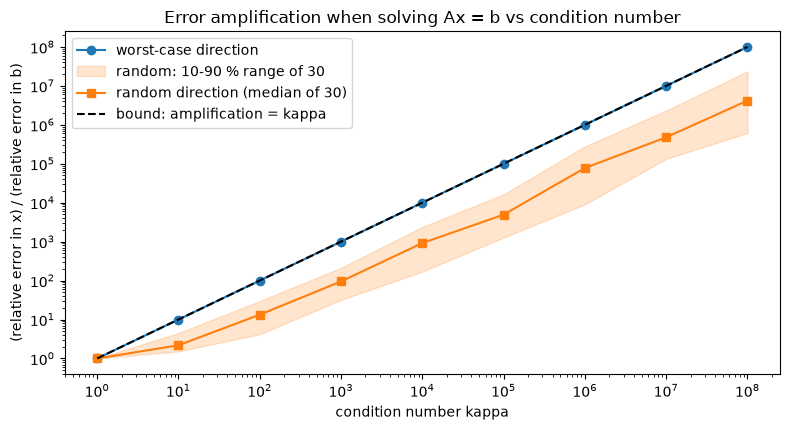

In [21]:
def random_orthogonal(n):
    Q, _ = np.linalg.qr(rng.normal(size=(n, n)))
    return Q

def matrix_with_condition(n, kappa):
    U, V = random_orthogonal(n), random_orthogonal(n)
    s = np.logspace(0, -np.log10(kappa), n)       # sigma from 1 down to 1/kappa
    return U @ np.diag(s) @ V.T, U, V, s

n = 8
kappas = np.logspace(0, 8, 9)
rng_amp = np.random.default_rng(1)                 # its own generator for the 30 random trials per kappa
amp_med, amp_lo, amp_hi, amp_worst = [], [], [], []
for kappa in kappas:
    A_k, U, V, s = matrix_with_condition(n, kappa)
    # 30 random right-hand sides, each perturbed in a random direction by one part in 1e8
    amps = []
    for _ in range(30):
        x_true = rng_amp.normal(size=n); b = A_k @ x_true
        db = rng_amp.normal(size=n); db = 1e-8 * np.linalg.norm(b) * db / np.linalg.norm(db)
        x_pert = np.linalg.solve(A_k, b + db)
        amps.append((np.linalg.norm(x_pert - x_true) / np.linalg.norm(x_true)) / 1e-8)
    amp_med.append(np.median(amps))
    amp_lo.append(np.percentile(amps, 10)); amp_hi.append(np.percentile(amps, 90))
    # worst case: b along u_1 (strong direction), db along u_n (weak direction)
    b_w = U[:, 0]; db_w = 1e-8 * U[:, -1]
    x_w = np.linalg.solve(A_k, b_w); x_wp = np.linalg.solve(A_k, b_w + db_w)
    amp_worst.append((np.linalg.norm(x_wp - x_w) / np.linalg.norm(x_w)) / 1e-8)
    print(f"kappa = {kappa:7.0e}:  np.linalg.cond = {np.linalg.cond(A_k):8.2e},"
          f"  amplification random (median of 30) {amp_med[-1]:8.2e},  worst case {amp_worst[-1]:8.2e}")

plt.figure(figsize=(8, 4.4))
plt.loglog(kappas, amp_worst, "o-", label="worst-case direction")
plt.fill_between(kappas, amp_lo, amp_hi, color="tab:orange", alpha=0.2, label="random: 10-90 % range of 30")
plt.loglog(kappas, amp_med, "s-", color="tab:orange", label="random direction (median of 30)")
plt.loglog(kappas, kappas, "k--", label="bound: amplification = kappa")
plt.title("Error amplification when solving Ax = b vs condition number")
plt.xlabel("condition number kappa"); plt.ylabel("(relative error in x) / (relative error in b)")
plt.legend(); plt.tight_layout(); plt.show()

The worst-case amplification sits exactly on the line $\kappa$ — the bound is tight. Random
perturbations do less damage — once $\kappa \ge 10^3$ the median of 30 trials sits roughly
10 to 25 times below the bound — but they still grow in proportion to $\kappa$: with $\kappa = 10^8$ a change in the
eighth decimal of $b$ can move $x$ in the first decimal. Rule of thumb: you lose up to
$\log_{10}\kappa$ digits.

### Why ill-conditioning slows gradient descent

On the quadratic $f(x) = \tfrac12 x^\top A x$ with eigenvalues $\lambda_{\max}$ and
$\lambda_{\min}$, gradient descent with the best fixed step $\eta = 2/(\lambda_{\max} +
\lambda_{\min})$ shrinks the error by $(\kappa - 1)/(\kappa + 1)$ per step. Let's count steps.

kappa =      1:      1 steps to shrink the error 1000x   (theory ~        1)
kappa =      2:      7 steps to shrink the error 1000x   (theory ~        6)
kappa =      5:     18 steps to shrink the error 1000x   (theory ~       17)
kappa =     10:     35 steps to shrink the error 1000x   (theory ~       34)
kappa =     30:    104 steps to shrink the error 1000x   (theory ~      104)
kappa =    100:    346 steps to shrink the error 1000x   (theory ~      345)
kappa =    300:   1037 steps to shrink the error 1000x   (theory ~     1036)
kappa =   1000:   3454 steps to shrink the error 1000x   (theory ~     3454)
kappa =   3000:  10362 steps to shrink the error 1000x   (theory ~    10362)
kappa =  10000:  34539 steps to shrink the error 1000x   (theory ~    34539)


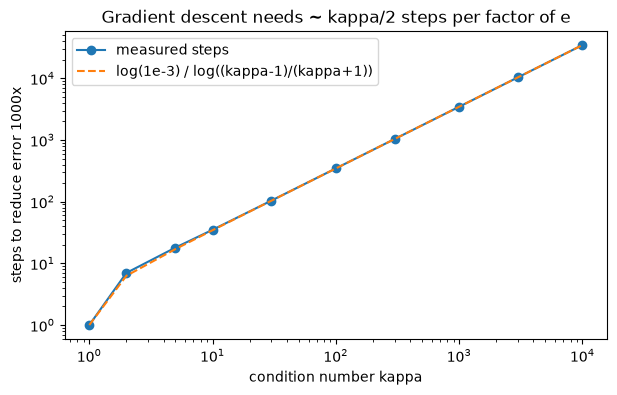

In [22]:
def gd_steps_to_tolerance(kappa, tol=1e-3, max_steps=200_000):
    A_q = np.diag([1.0, kappa])                    # eigenvalues 1 and kappa
    eta = 2.0 / (1.0 + kappa)                      # optimal fixed step size
    x = np.array([1.0, 1.0]); x0_norm = np.linalg.norm(x)
    for step in range(1, max_steps + 1):
        x = x - eta * (A_q @ x)                    # gradient of 0.5 x^T A x is A x
        if np.linalg.norm(x) < tol * x0_norm:
            return step
    return max_steps

kappas_gd = np.array([1, 2, 5, 10, 30, 100, 300, 1000, 3000, 10000])
steps = np.array([gd_steps_to_tolerance(k) for k in kappas_gd])
ratio = (kappas_gd - 1) / (kappas_gd + 1)
predicted = np.ones_like(kappas_gd, dtype=float)
predicted[kappas_gd > 1] = np.log(1e-3) / np.log(ratio[kappas_gd > 1])   # kappa = 1 converges in one step
for k_, s_, p_ in zip(kappas_gd, steps, predicted):
    print(f"kappa = {k_:6d}: {s_:6d} steps to shrink the error 1000x   (theory ~ {p_:8.0f})")

plt.loglog(kappas_gd, steps, "o-", label="measured steps")
plt.loglog(kappas_gd, predicted, "--", label="log(1e-3) / log((kappa-1)/(kappa+1))")
plt.title("Gradient descent needs ~ kappa/2 steps per factor of e")
plt.xlabel("condition number kappa"); plt.ylabel("steps to reduce error 1000x"); plt.legend(); plt.show()

The step count grows linearly with $\kappa$: ten times worse conditioning, ten times more
iterations. Since $\log\frac{\kappa+1}{\kappa-1} \approx 2/\kappa$, each factor of $e$ costs
about $\kappa/2$ steps, and three digits cost about $\tfrac{\kappa}{2}\ln 1000 \approx
3.45\,\kappa$ steps. Where do all those steps go? Draw the iterates on the level sets of the
same quadratic.

kappa =  3: point after 15 steps = [ 0. -0.],  ratio per step = 0.5000
kappa = 30: point after 15 steps = [ 0.3677 -0.3677],  ratio per step = 0.9355


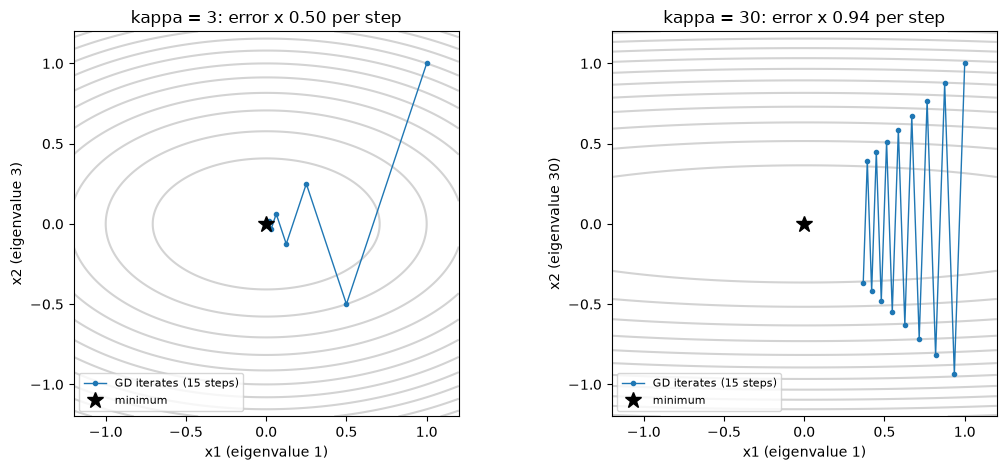

In [23]:
g1, g2 = np.meshgrid(np.linspace(-1.2, 1.2, 200), np.linspace(-1.2, 1.2, 200))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, kap in zip(axes, [3, 30]):
    eta_ = 2 / (1 + kap)                                   # the same optimal step as above
    path = [np.array([1., 1.])]
    for _ in range(15):
        path.append(path[-1] - eta_ * np.array([1., kap]) * path[-1])
    path = np.array(path)
    print(f"kappa = {kap:2d}: point after 15 steps = {path[-1]},  ratio per step = {(kap - 1) / (kap + 1):.4f}")
    ax.contour(g1, g2, 0.5 * (g1 ** 2 + kap * g2 ** 2), levels=12, colors="lightgray")
    ax.plot(path[:, 0], path[:, 1], "o-", color="tab:blue", ms=3, lw=1, label="GD iterates (15 steps)")
    ax.plot(0, 0, "k*", ms=12, label="minimum")
    ax.set_aspect("equal"); ax.set_xlim(-1.2, 1.2); ax.set_ylim(-1.2, 1.2)
    ax.set_title(f"kappa = {kap}: error x {(kap - 1) / (kap + 1):.2f} per step")
    ax.set_xlabel("x1 (eigenvalue 1)"); ax.set_ylabel(f"x2 (eigenvalue {kap})")
    ax.legend(loc="lower left", fontsize=8)
plt.tight_layout(); plt.show()

**Notice that** with $\kappa = 3$ the iterates reach the minimum in a handful of steps, while
with $\kappa = 30$ every step overshoots across the steep $x_2$ direction and the error shrinks
only by $29/31 \approx 0.94$ per step, so after 15 steps the point is still at $x_1 \approx 0.37$.
The zig-zag is the step-count table above, drawn. Module 05 shows how momentum and Adam attack
this; the cheapest fix of all is to make $\kappa$ small in the first place by **scaling the
features**.

In [24]:
# A polynomial-trend design matrix on raw calendar years vs centred years
years = np.arange(1990, 2021, dtype=float)
X_raw = np.column_stack([np.ones_like(years), years, years ** 2])
X_cen = np.column_stack([np.ones_like(years), years - 2005, (years - 2005) ** 2])
print("condition number, raw years:     %.2e" % np.linalg.cond(X_raw))
print("condition number, centred years: %.2e" % np.linalg.cond(X_cen))

# Correlated features with wildly different scales, before and after standardising
Z = rng.normal(size=(500, 3)) @ np.array([[1, 0.9, 0.0], [0, 0.4, 0.0], [0, 0, 1.0]])
Z = Z * np.array([1.0, 1000.0, 0.01])        # different units
Z_std = (Z - Z.mean(axis=0)) / Z.std(axis=0)
print("\ncondition number of X^T X, raw features:          %.2e" % np.linalg.cond(Z.T @ Z))
print("condition number of X^T X, standardised features: %.2e" % np.linalg.cond(Z_std.T @ Z_std))
print("(the remaining conditioning comes from the 0.9 correlation, which scaling cannot remove)")

condition number, raw years:     2.26e+11
condition number, centred years: 1.61e+02

condition number of X^T X, raw features:          8.46e+09
condition number of X^T X, standardised features: 1.97e+01
(the remaining conditioning comes from the 0.9 correlation, which scaling cannot remove)


Centring the year variable cuts the condition number from about $10^{11}$ to about $10^2$ —
same model, same fitted curve, nine orders of magnitude less error amplification.
Standardising the three-feature design matrix removes the damage done by units; what remains
is genuine correlation between features, which only regularisation (Section 7, Module 13)
or dropping features can address.

**Try it yourself:** in `gd_steps_to_tolerance`, use the "safe" step `eta = 1.0 / kappa`
instead of the optimal one. How does the step count change?

## Summary

- Eigenvectors are the directions a square matrix only stretches; for a $2\times2$ matrix
  the eigenvalues solve $\lambda^2 - \operatorname{tr}A\,\lambda + \det A = 0$.
- $A^k = PD^kP^{-1}$: the dominant eigenvalue takes over, which is why power iteration
  works, why Markov chains converge to the eigenvector with eigenvalue 1, and why PageRank
  with damping converges in a few dozen steps.
- Symmetric matrices have real eigenvalues and orthonormal eigenvectors ($A = Q\Lambda Q^\top$);
  positive semidefinite means all $\lambda_i \ge 0$, and the Rayleigh quotient lives in
  $[\lambda_{\min}, \lambda_{\max}]$.
- Every matrix has an SVD $A = U\Sigma V^\top$: rotate, stretch, rotate. Singular values
  reveal rank, norms and noise floors.
- Truncating the SVD at rank $k$ is the best rank-$k$ approximation (Eckart–Young), with
  error exactly $\sqrt{\sum_{i>k}\sigma_i^2}$ — the basis of compression, denoising and LoRA.
- PCA = eigenvectors of the covariance = right singular vectors of the centred data;
  scikit-learn agrees to machine precision; scale your features first.
- The pseudo-inverse $V\Sigma^+U^\top$ gives the minimum-norm least-squares solution even
  for rank-deficient problems; ridge regression is a soft version of its cut-off.
- The condition number $\sigma_{\max}/\sigma_{\min}$ bounds error amplification exactly and
  sets the number of gradient-descent steps; centring and standardising shrink it.

## Next: open `exercises.ipynb`

Twelve exercises (nine with instant self-checks, two conceptual questions and a mini-project),
from eigenvalues by hand to a latent-factor recommender built from truncated SVDs.